In [1]:
from getdist import loadMCSamples
import numpy as np
from getdist import MCSamples
from pathlib import Path

replacements = {
    "H0": r"H_0\, [\mathrm{km/s/Mpc}]",
    "sigma8": r"\sigma_8",
    "S8": r"S_8",
    "rd_star": r"r_d^\star\, [\mathrm{Mpc}]",
    "rs_star": r"r_s^\star\, [\mathrm{Mpc}]",
    "omega_b": r"\omega_b",
    "omega_cdm": r"\omega_\text{cdm}",
    "tau_reio": r"\tau_\text{reio}",
    "ln10^{10}A_s": r"\ln 10^{10}A_s",
    "n_s": r"n_s",
    "S8": r"S_8",
    "rd_star": r"r_d^\star",
    "rs_star": r"r_s^\star",
}
def load_samples(chain_dir, param_names, ignore_rows=0.2):
    chain_dir = Path(chain_dir)
    paramfiles = list(chain_dir.glob("*.paramnames"))
    if not paramfiles:
        raise FileNotFoundError("No .paramnames file found in directory")
    if len(paramfiles) > 1:
        print(f"WARNING: multiple .paramnames found, using {paramfiles[0].name}")

    root = str(paramfiles[0])[:-len(".paramnames")]
    samples = loadMCSamples(root, settings={'ignore_rows': ignore_rows})

    # apply LaTeX label overrides
    for p in samples.paramNames.names:
        if p.name in replacements:
            p.label = replacements[p.name]

    # apply hard prior ranges, only if present in this chain
    existing = {p.name for p in samples.paramNames.names}
    for pname in ['fraction_maxion_ac__1', 'fraction_maxion_ac__2',
                  'fraction_maxion_ac__3', 'fraction_maxion_ac__4']:
        if pname in existing:
            samples.setRanges({pname: (0., 0.3)})

    return samples

In [2]:
from pathlib import Path

BASE = Path(
    "/Users/bellamarco01/uni/omega_m/chains"
)
# chain_2psd = BASE / "camspec_spt_act_lensing_pantheon_desi_sh0es_2026-07-14"
chain = BASE / "test2"


# param_names =['Omega_m', 'sigma8','H0','omega_cdm', 'S8', 'rs_star']
param_names =['h','omega_b','omega_m0', 'tau_reio',"n_s",'ln10^{10}A_s']
# param_names = ['h','Om_bin0', 'Om_bin1', 'Om_bin2', "omega_b",
#     "tau_reio",
#     "n_s",
#     "ln10^{10}A_s"]

samp = load_samples(
    chain,
    param_names
)


/Users/bellamarco01/.pyenv/versions/3.13.5/lib/python3.13/site-packages/plotting/plotting.py


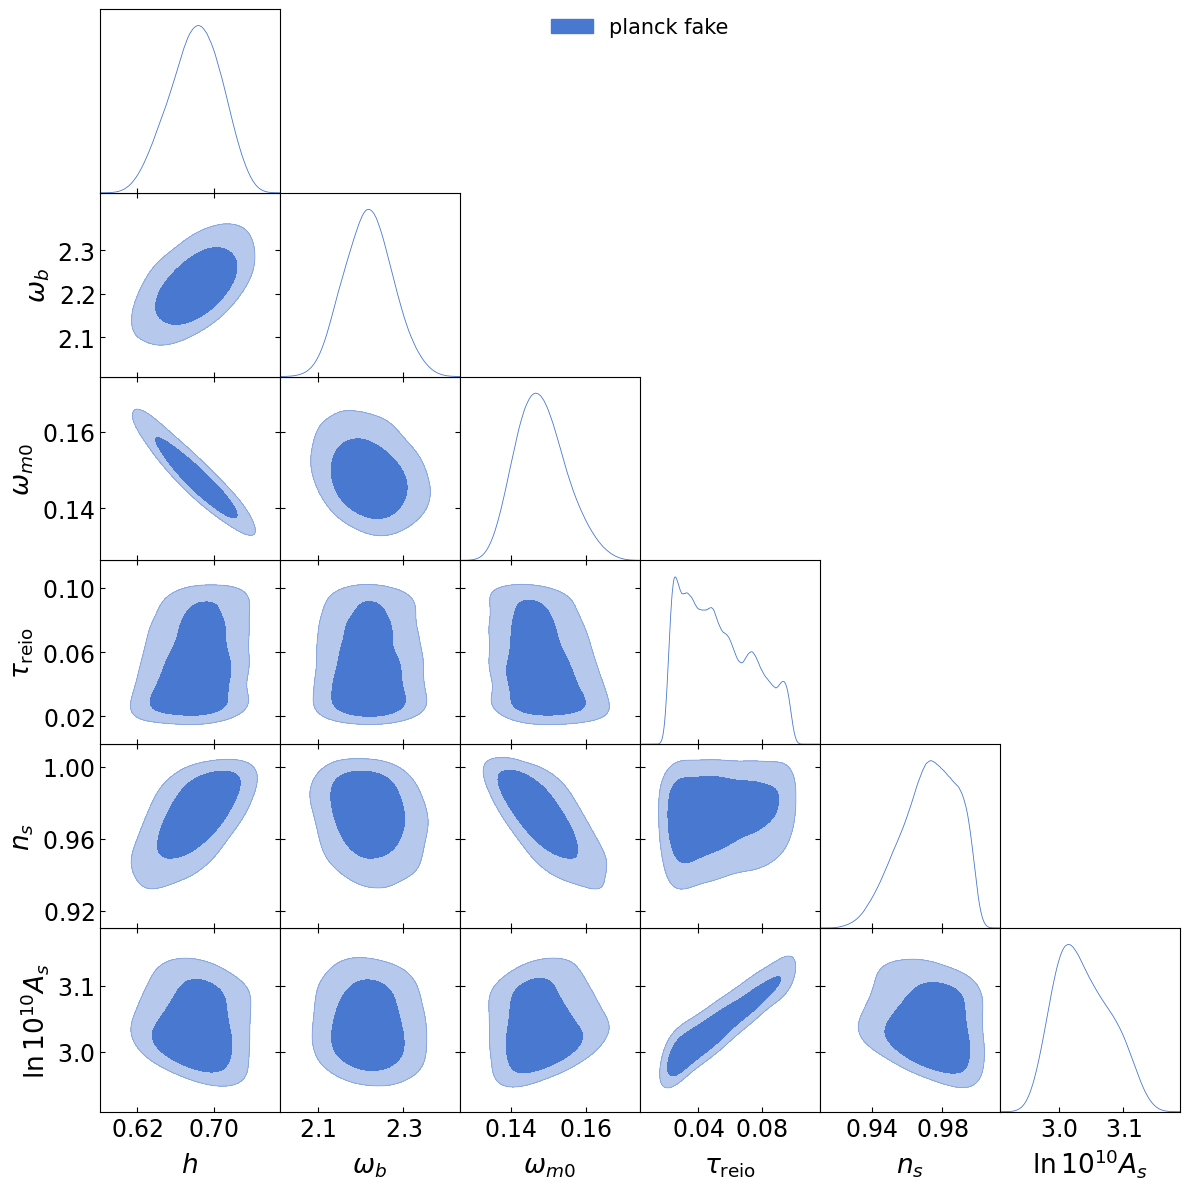

In [3]:
from getdist import plots
import matplotlib.pyplot as plt
import plotting.plotting as pl
print(pl.__file__)

g = pl.my_plotter()
# g = plots.get_subplot_plotter()
# Make all text bigger
g.settings.axes_fontsize = 20     # tick labels
g.settings.lab_fontsize = 22      # axis labels
g.settings.legend_fontsize = 18   # legend
g.settings.figure_legend_frame = False  # optional, cleaner look

g.triangle_plot(
    [samp],
    params=param_names,
    filled=True,
    legend_labels=[
        r"planck fake",
    ],
)

plt.show()


# Debug: 1-sigma intervals for all input parameters, true LCDM fake likelihood

### set a fake planck likelihood for lambdaCDM with simple noise, to check that our pipeline works fine


In [4]:
# Fiducial (true) values used to generate the mock chains, for comparison.
FIDUCIAL_PARAMS = {
    "omega_b": 2.24,
    "h": 0.674,
    "tau_reio": 0.054,
    "n_s": 0.965,
    "ln10^{10}A_s": 3.044,
    'omega_m0': 0.15,
}

# a couple of chain parameters aren't named/scaled the same as the fiducial dict
# (H0 = 100*h), so map those explicitly: chain_name -> (fiducial_key, scale)
NAME_MAP = {
    "H0": ("h", 100.0),
}

def get_fiducial(name):
    if name in FIDUCIAL_PARAMS:
        return FIDUCIAL_PARAMS[name]
    if name in NAME_MAP:
        fid_key, scale = NAME_MAP[name]
        if fid_key in FIDUCIAL_PARAMS:
            return FIDUCIAL_PARAMS[fid_key] * scale
    return None

stats = samp.getMargeStats()

print(f"{'param':<12} {'mean':>10} {'std':>10} {'-1sigma':>10} {'+1sigma':>10}   68% range          fiducial     pull(sigma)")
print("-" * 110)
for name in param_names:
    par = stats.parWithName(name)
    lims = par.limits[0]  # 68%
    fid = get_fiducial(name)
    fid_str = f"{fid:>10.4f}" if fid is not None else f"{'--':>10}"
    pull_str = f"{(par.mean - fid) / par.err:>+8.2f}" if fid is not None else f"{'--':>8}"
    print(f"{name:<12} {par.mean:>10.4f} {par.err:>10.4f} "
          f"{lims.lower - par.mean:>+10.4f} {lims.upper - par.mean:>+10.4f}   "
          f"[{lims.lower:.4f}, {lims.upper:.4f}]   {fid_str}   {pull_str}")

print()
for name in param_names:
    print(samp.getInlineLatex(name, limit=1))

param              mean        std    -1sigma    +1sigma   68% range          fiducial     pull(sigma)
--------------------------------------------------------------------------------------------------------------
h                0.6813     0.0272    -0.0253    +0.0301   [0.6560, 0.7114]       0.6740      +0.27
omega_b          2.2185     0.0578    -0.0612    +0.0580   [2.1573, 2.2765]       2.2400      -0.37
omega_m0         0.1481     0.0068    -0.0077    +0.0058   [0.1404, 0.1539]       0.1500      -0.28
tau_reio         0.0523     0.0219    -0.0311    +0.0220   [0.0212, 0.0743]       0.0540      -0.08
n_s              0.9728     0.0159    -0.0116    +0.0209   [0.9613, 0.9937]       0.9650      +0.49
ln10^{10}A_s     3.0379     0.0437    -0.0535    +0.0369   [2.9844, 3.0748]       3.0440      -0.14

h = 0.681^{+0.030}_{-0.025}
\omega_b = 2.219\pm 0.058
\omega{}_{m0 } = 0.1481^{+0.0058}_{-0.0077}
\tau_\text{reio} = 0.052^{+0.022}_{-0.031}
n_s = 0.973^{+0.021}_{-0.012}
\ln 10^{10}A_s

# Part 2: try hiding two different masses in Planck data

We will work with a fake Planck likelihood, generated from mock CMB spectra with omega_m = [0.12, 0.17] for low l (l<1250) and high l (l>1250), to check if our pipeline can detect the two different values hidden in the data.

In [5]:
from pathlib import Path

# chain_2psd = BASE / "camspec_spt_act_lensing_pantheon_desi_sh0es_2026-07-14"
chain2v2 = BASE / "two_bins_vs_two_bins"


# param_names =['Omega_m', 'sigma8','H0','omega_cdm', 'S8', 'rs_star']
param_names2 =['h','omega_b','omega_m0', 'omega_m1', 'tau_reio',"n_s",'ln10^{10}A_s']
# param_names = ['h','Om_bin0', 'Om_bin1', 'Om_bin2', "omega_b",
#     "tau_reio",
#     "n_s",
#     "ln10^{10}A_s"]

samp2 = load_samples(
    chain2v2,
    param_names2
)


## Binned Omega_m violin plot

Extract the weighted MCMC samples for the binned $\Omega_m$ parameters (`Om_bin0`, `Om_bin1`, ...) and show their posteriors as violin plots, one per bin.

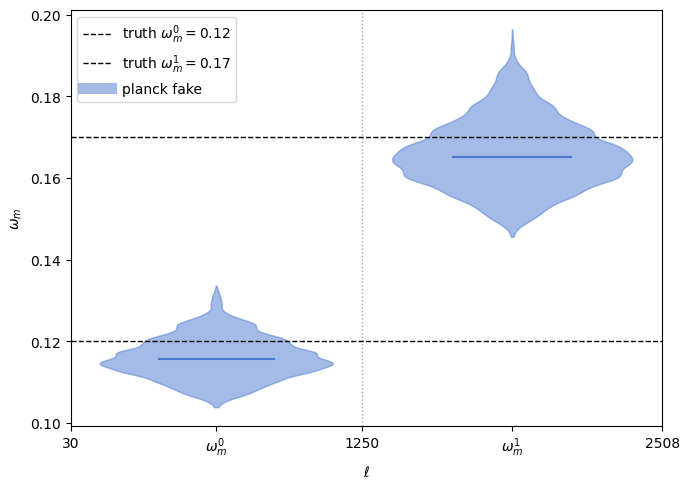

omega_m0: 0.1156 (+0.0056 / -0.0048)
omega_m1: 0.1652 (+0.0090 / -0.0075)
param              mean        std    -1sigma    +1sigma   68% range          fiducial     pull(sigma)
--------------------------------------------------------------------------------------------------------------
h                0.6867     0.0276    -0.0285    +0.0289   [0.6581, 0.7155]       0.6740      +0.46
omega_b          2.2292     0.0600    -0.0588    +0.0600   [2.1705, 2.2892]       2.2400      -0.18
omega_m0         0.1160     0.0051    -0.0057    +0.0046   [0.1103, 0.1206]       0.1200      -0.79
omega_m1         0.1658     0.0083    -0.0093    +0.0072   [0.1566, 0.1730]       0.1700      -0.50
tau_reio         0.0484     0.0208    -0.0273    +0.0105   [0.0212, 0.0589]       0.0540      -0.27
n_s              0.9763     0.0145    -0.0106    +0.0191   [0.9656, 0.9954]       0.9650      +0.78
ln10^{10}A_s     3.0222     0.0419    -0.0527    +0.0300   [2.9695, 3.0522]       3.0440      -0.52



In [6]:
import re
import numpy as np
import matplotlib.pyplot as plt

TRUTH_VALUES = {0: 0.12, 1: 0.17}  # bin index -> injected truth value

def _bin_index(name, prefix):
    """Extract trailing integer regardless of separator style
    (Om_bin0, omega_m__0, omega_m_0, ...)."""
    m = re.search(r"(\d+)$", name)
    if m is None or not name.startswith(prefix):
        return None
    return int(m.group(1))


def get_binned_samples(samp, prefix="omega_m", n_resample=20000, seed=42):
    all_names = [p.name for p in samp.getParamNames().names]
    indexed = [(n, _bin_index(n, prefix)) for n in all_names]
    indexed = [(n, i) for n, i in indexed if i is not None]
    if not indexed:
        raise ValueError(f"No parameters starting with '{prefix}' found in samples")

    indexed.sort(key=lambda t: t[1])
    param_names = [n for n, _ in indexed]
    bin_indices = [i for _, i in indexed]

    rng = np.random.default_rng(seed)
    weights = samp.weights
    probs = weights / weights.sum()
    resampled = {}
    params = samp.getParams()
    for name in param_names:
        values = getattr(params, name)
        idx = rng.choice(len(values), size=n_resample, p=probs, replace=True)
        resampled[name] = values[idx]
    return param_names, bin_indices, resampled


def plot_omegam_violin(samp, prefix="omega_m", l_edges=(30, 1250, 2508),
                        n_resample=20000, ax=None, color="C0", label=None,
                        truth_values=TRUTH_VALUES):
    """
    Violin plot of binned Omega_m posteriors, positioned along the
    ell axis at the bin they apply to (e.g. bin0 -> l in [30,1250],
    bin1 -> l in [1250,2508]).
    """
    param_names, bin_indices, resampled = get_binned_samples(
        samp, prefix=prefix, n_resample=n_resample
    )
    n_bins = len(param_names)

    l_edges = np.asarray(l_edges, dtype=float)
    if len(l_edges) != n_bins + 1:
        raise ValueError(
            f"l_edges must have length n_bins+1={n_bins+1}, got {len(l_edges)}"
        )
    positions = 0.5 * (l_edges[:-1] + l_edges[1:])
    widths = 0.8 * np.diff(l_edges)

    data = [resampled[name] for name in param_names]
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))

    parts = ax.violinplot(
        data,
        positions=positions,
        widths=widths,
        showmeans=False,
        showmedians=True,
        showextrema=False,
    )
    for pc in parts["bodies"]:
        pc.set_facecolor(color)
        pc.set_alpha(0.5)
        pc.set_edgecolor(color)
    parts["cmedians"].set_color(color)

    # global label remap: omega_m{i} -> \omega_m^{i}, used as violin
    # x-tick labels placed at each bin's center
    tick_labels = [rf"$\omega_m^{{{i}}}$" for i in bin_indices]
    ax.set_xticks(positions)
    ax.set_xticklabels(tick_labels)

    # secondary axis-style annotation: show the actual ell switch points
    for edge in l_edges[1:-1]:  # interior switches only (1250 here)
        ax.axvline(edge, color="gray", linestyle=":", linewidth=1, alpha=0.7)
    ax.set_xlim(l_edges[0], l_edges[-1])
    extra_ticks = sorted(set(l_edges.tolist()))
    ax.set_xticks(list(positions) + extra_ticks)
    ax.set_xticklabels(tick_labels + [f"{int(e)}" for e in extra_ticks])
    ax.set_xlabel(r"$\ell$")

    ax.set_ylabel(r"$\omega_m$")

    # horizontal truth lines
    if truth_values:
        for i, y in truth_values.items():
            ax.axhline(y, color="k", linestyle="--", linewidth=1,
                        label=rf"truth $\omega_m^{{{i}}}={y}$")

    if label is not None:
        ax.plot([], [], color=color, alpha=0.5, linewidth=8, label=label)
    ax.legend()
    return ax, param_names, resampled


ax, binned_names, binned_samples = plot_omegam_violin(
    samp2,
    prefix="omega_m",
    l_edges=(30, 1250, 2508),
    label="planck fake",
)
plt.tight_layout()

plt.show()

for name in binned_names:
    vals = binned_samples[name]
    lo, med, hi = np.percentile(vals, [16, 50, 84])
    print(f"{name}: {med:.4f} (+{hi-med:.4f} / -{med-lo:.4f})")
# Fiducial (true) values used to generate the mock chains, for comparison.
FIDUCIAL_PARAMS = {
    "omega_b": 2.24,
    "h": 0.674,
    "tau_reio": 0.054,
    "n_s": 0.965,
    "ln10^{10}A_s": 3.044,
    'omega_m0': 0.12,
    'omega_m1': 0.17,
}

# a couple of chain parameters aren't named/scaled the same as the fiducial dict
# (H0 = 100*h), so map those explicitly: chain_name -> (fiducial_key, scale)

stats = samp2.getMargeStats()

print(f"{'param':<12} {'mean':>10} {'std':>10} {'-1sigma':>10} {'+1sigma':>10}   68% range          fiducial     pull(sigma)")
print("-" * 110)
for name in param_names2:
    par = stats.parWithName(name)
    lims = par.limits[0]  # 68%
    fid = get_fiducial(name)
    fid_str = f"{fid:>10.4f}" if fid is not None else f"{'--':>10}"
    pull_str = f"{(par.mean - fid) / par.err:>+8.2f}" if fid is not None else f"{'--':>8}"
    print(f"{name:<12} {par.mean:>10.4f} {par.err:>10.4f} "
          f"{lims.lower - par.mean:>+10.4f} {lims.upper - par.mean:>+10.4f}   "
          f"[{lims.lower:.4f}, {lims.upper:.4f}]   {fid_str}   {pull_str}")

print()

# what happens with 3 bins vs 2 different omega_m's?

In [7]:
from pathlib import Path

# chain_2psd = BASE / "camspec_spt_act_lensing_pantheon_desi_sh0es_2026-07-14"
chain3v2 = BASE / "three_bins_vs_two_bins"


# param_names =['Omega_m', 'sigma8','H0','omega_cdm', 'S8', 'rs_star']
param_names3 =['h','omega_b','omega_m0', 'omega_m1', 'omega_m2', 'tau_reio',"n_s",'ln10^{10}A_s']
# param_names = ['h','Om_bin0', 'Om_bin1', 'Om_bin2', "omega_b",
#     "tau_reio",
#     "n_s",
#     "ln10^{10}A_s"]

samp3 = load_samples(
    chain3v2,
    param_names3
)


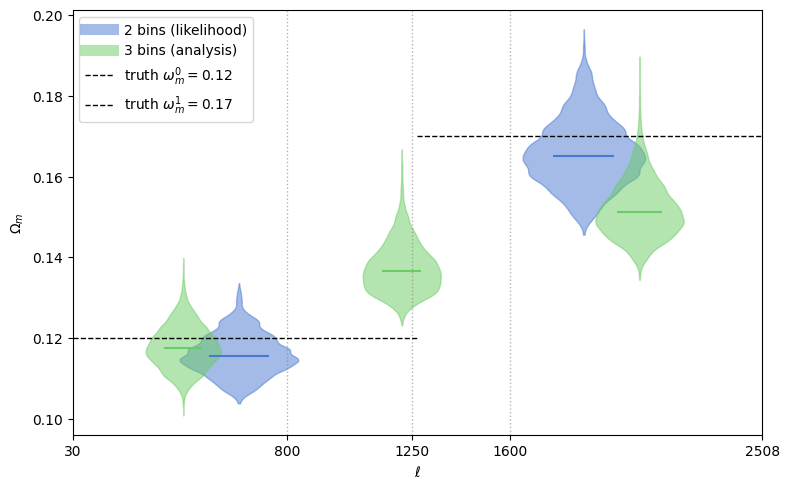

--- 2 bins (likelihood) ---
omega_m0: 0.1156 (+0.0056 / -0.0048)
omega_m1: 0.1652 (+0.0090 / -0.0075)
--- 3 bins (analysis) ---
omega_m0: 0.1176 (+0.0058 / -0.0052)
omega_m1: 0.1367 (+0.0070 / -0.0053)
omega_m2: 0.1512 (+0.0079 / -0.0059)


In [10]:
import re
import numpy as np
import matplotlib.pyplot as plt

TRUTH_VALUES = {0: 0.12, 1: 0.17}  # bin index -> injected truth value (2-bin likelihood)


def _bin_index(name, prefix):
    m = re.search(r"(\d+)$", name)
    if m is None or not name.startswith(prefix):
        return None
    return int(m.group(1))


def get_binned_samples(samp, prefix="omega_m", n_resample=20000, seed=42):
    all_names = [p.name for p in samp.getParamNames().names]
    indexed = [(n, _bin_index(n, prefix)) for n in all_names]
    indexed = [(n, i) for n, i in indexed if i is not None]
    if not indexed:
        raise ValueError(f"No parameters starting with '{prefix}' found in samples")

    indexed.sort(key=lambda t: t[1])
    param_names = [n for n, _ in indexed]
    bin_indices = [i for _, i in indexed]

    rng = np.random.default_rng(seed)
    weights = samp.weights
    probs = weights / weights.sum()
    resampled = {}
    params = samp.getParams()
    for name in param_names:
        values = getattr(params, name)
        idx = rng.choice(len(values), size=n_resample, p=probs, replace=True)
        resampled[name] = values[idx]
    return param_names, bin_indices, resampled


def _add_violin_group(ax, samp, prefix, l_edges, n_resample, color, label,
                       width_frac=0.35, x_shift=0.0):
    """
    Draws one chain's binned violins on `ax`, positioned at the ell-bin
    centers implied by l_edges, optionally shifted sideways (x_shift) so
    two chains with overlapping bin edges (e.g. a shared switch at 1250)
    don't draw on top of each other.
    """
    param_names, bin_indices, resampled = get_binned_samples(
        samp, prefix=prefix, n_resample=n_resample
    )
    n_bins = len(param_names)

    l_edges = np.asarray(l_edges, dtype=float)
    if len(l_edges) != n_bins + 1:
        raise ValueError(
            f"l_edges must have length n_bins+1={n_bins+1} for prefix "
            f"'{prefix}' ({n_bins} bins found), got {len(l_edges)}"
        )
    centers = 0.5 * (l_edges[:-1] + l_edges[1:])
    positions = centers + x_shift
    widths = width_frac * np.diff(l_edges)

    data = [resampled[name] for name in param_names]
    parts = ax.violinplot(
        data, positions=positions, widths=widths,
        showmeans=False, showmedians=True, showextrema=False,
    )
    for pc in parts["bodies"]:
        pc.set_facecolor(color)
        pc.set_alpha(0.5)
        pc.set_edgecolor(color)
    parts["cmedians"].set_color(color)

    if label is not None:
        ax.plot([], [], color=color, alpha=0.5, linewidth=8, label=label)

    return param_names, bin_indices, resampled, l_edges


def plot_omegam_violin_multi(groups, truth_values=TRUTH_VALUES, n_resample=20000,
                              ax=None, width_frac=0.35, shift=25.0):
    """
    Overlay several binned-omega_m posteriors (e.g. a 2-bin likelihood
    run and a 3-bin analysis run) on one ell-axis plot.

    Parameters
    ----------
    groups : list of dict, each with keys:
        samp   : getdist.MCSamples
        prefix : str, e.g. "omega_m"
        l_edges: array-like, length n_bins+1, in ell
        color  : matplotlib color
        label  : legend label, e.g. "2 bins (likelihood)"
    truth_values : dict {bin_index: value}, drawn as horizontal dashed
        lines spanning the full x-range (set to None to skip)
    shift : horizontal offset (in ell) applied per group, so violins
        from different groups sharing an edge (e.g. both having a bin
        boundary at 1250) don't overplot each other
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    all_edges = set()
    results = []
    n_groups = len(groups)
    for gi, g in enumerate(groups):
        # center the group offsets around 0: e.g. for 2 groups, shifts are -shift/2, +shift/2
        x_shift = (gi - (n_groups - 1) / 2) * shift
        param_names, bin_indices, resampled, l_edges = _add_violin_group(
            ax, g["samp"], g["prefix"], g["l_edges"], n_resample,
            g.get("color", f"C{gi}"), g.get("label"),
            width_frac=width_frac, x_shift=x_shift,
        )
        all_edges.update(l_edges.tolist())
        results.append({
            "param_names": param_names,
            "bin_indices": bin_indices,
            "resampled": resampled,
            "l_edges": l_edges,
            "label": g.get("label"),
        })

    all_edges = sorted(all_edges)
    for edge in all_edges[1:-1]:
        ax.axvline(edge, color="gray", linestyle=":", linewidth=1, alpha=0.6)
    ax.set_xlim(min(all_edges), max(all_edges))
    ax.set_xticks(all_edges)
    ax.set_xticklabels([f"{int(e)}" for e in all_edges])
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel(r"$\Omega_m$")

    if truth_values:
        n_truth = len(truth_values)
        for j, (i, y) in enumerate(sorted(truth_values.items())):
            ax.axhline(
                y,
                color="k",
                linestyle="--",
                linewidth=1,
                xmin=j / n_truth,
                xmax=(j + 1) / n_truth,
                label=rf"truth $\omega_m^{{{i}}}={y}$",
            )

    ax.legend()
    return ax, results


# ---- example usage: 2-bin likelihood vs 3-bin analysis ----
# Fill in the actual switch points for your 3-bin analysis run --
# I don't know these, this is a placeholder split of the same ell range.
l_edges_2bin = (30, 1250, 2508)
l_edges_3bin = (30, 800, 1600, 2508)   # <-- REPLACE with your real 3-bin l_switch values

ax, results = plot_omegam_violin_multi(
    groups=[
        dict(samp=samp2, prefix="omega_m", l_edges=l_edges_2bin,
             color="C0", label="2 bins (likelihood)"),
        dict(samp=samp3, prefix="omega_m", l_edges=l_edges_3bin,
             color="C1", label="3 bins (analysis)"),
    ],
)
plt.tight_layout()
plt.show()

for res in results:
    print(f"--- {res['label']} ---")
    for name in res["param_names"]:
        vals = res["resampled"][name]
        lo, med, hi = np.percentile(vals, [16, 50, 84])
        print(f"{name}: {med:.4f} (+{hi-med:.4f} / -{med-lo:.4f})")

In [11]:
# Fiducial (true) values used to generate the mock chains, for comparison.
FIDUCIAL_PARAMS = {
    "omega_b": 2.24,
    "h": 0.674,
    "tau_reio": 0.054,
    "n_s": 0.965,
    "ln10^{10}A_s": 3.044,
    'omega_m0': 0.12,
    'omega_m1': np.nan,
    'omega_m2': 0.17,
}

# a couple of chain parameters aren't named/scaled the same as the fiducial dict
# (H0 = 100*h), so map those explicitly: chain_name -> (fiducial_key, scale)

stats = samp3.getMargeStats()

print(f"{'param':<12} {'mean':>10} {'std':>10} {'-1sigma':>10} {'+1sigma':>10}   68% range          fiducial     pull(sigma)")
print("-" * 110)
for name in param_names3:
    par = stats.parWithName(name)
    lims = par.limits[0]  # 68%
    fid = get_fiducial(name)
    fid_str = f"{fid:>10.4f}" if fid is not None else f"{'--':>10}"
    pull_str = f"{(par.mean - fid) / par.err:>+8.2f}" if fid is not None else f"{'--':>8}"
    print(f"{name:<12} {par.mean:>10.4f} {par.err:>10.4f} "
          f"{lims.lower - par.mean:>+10.4f} {lims.upper - par.mean:>+10.4f}   "
          f"[{lims.lower:.4f}, {lims.upper:.4f}]   {fid_str}   {pull_str}")

print()

param              mean        std    -1sigma    +1sigma   68% range          fiducial     pull(sigma)
--------------------------------------------------------------------------------------------------------------
h                0.7105     0.0264    -0.0130    +0.0363   [0.6975, 0.7468]       0.6740      +1.38
omega_b          2.1384     0.0636    -0.0639    +0.0638   [2.0745, 2.2022]       2.2400      -1.60
omega_m0         0.1179     0.0054    -0.0059    +0.0048   [0.1119, 0.1227]       0.1200      -0.40
omega_m1         0.1374     0.0062    -0.0074    +0.0042   [0.1300, 0.1416]          nan       +nan
omega_m2         0.1521     0.0072    -0.0083    +0.0052   [0.1438, 0.1572]       0.1700      -2.49
tau_reio         0.0655     0.0225    -0.0133    +0.0334   [0.0522, 0.0989]       0.0540      +0.51
n_s              0.9591     0.0173    -0.0183    +0.0181   [0.9408, 0.9772]       0.9650      -0.34
ln10^{10}A_s     3.0778     0.0464    -0.0411    +0.0571   [3.0366, 3.1349]       3.04

# Correlations between the varios omega_ms

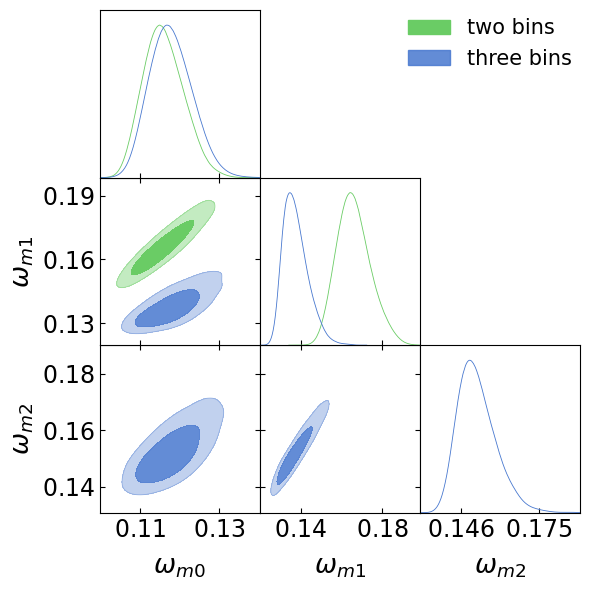

In [12]:
from getdist import plots
import matplotlib.pyplot as plt
import plotting.plotting as pl

g = pl.my_plotter()
# g = plots.get_subplot_plotter()
# Make all text bigger
g.settings.axes_fontsize = 20     # tick labels
g.settings.lab_fontsize = 22      # axis labels
g.settings.legend_fontsize = 18   # legend
g.settings.figure_legend_frame = False  # optional, cleaner look

param_names3 =['omega_m0', 'omega_m1', 'omega_m2']
g.triangle_plot(
    [samp2,samp3],
    params=param_names3,
    filled=True,
    legend_labels=[
        r"two bins",
        r"three bins",
    ],
)

plt.show()


# Try with 4 lol


In [13]:
from pathlib import Path

# chain_2psd = BASE / "camspec_spt_act_lensing_pantheon_desi_sh0es_2026-07-14"
chain4v2 = BASE / "four_bins_vs_two_bins"


# param_names =['Omega_m', 'sigma8','H0','omega_cdm', 'S8', 'rs_star']
param_names4 =['h','omega_b','omega_m0', 'omega_m1', 'omega_m2', 'omega_m3', 'tau_reio',"n_s",'ln10^{10}A_s']
# param_names = ['h','Om_bin0', 'Om_bin1', 'Om_bin2', "omega_b",
#     "tau_reio",
#     "n_s",
#     "ln10^{10}A_s"]

samp4 = load_samples(
    chain4v2,
    param_names4
)

/Users/bellamarco01/uni/omega_m/chains/four_bins_vs_two_bins/2026-07-20_30000__1.txt
/Users/bellamarco01/uni/omega_m/chains/four_bins_vs_two_bins/2026-07-20_30000__2.txt
/Users/bellamarco01/uni/omega_m/chains/four_bins_vs_two_bins/2026-07-20_30000__3.txt
/Users/bellamarco01/uni/omega_m/chains/four_bins_vs_two_bins/2026-07-20_30000__4.txt
Removed 0.2 as burn in


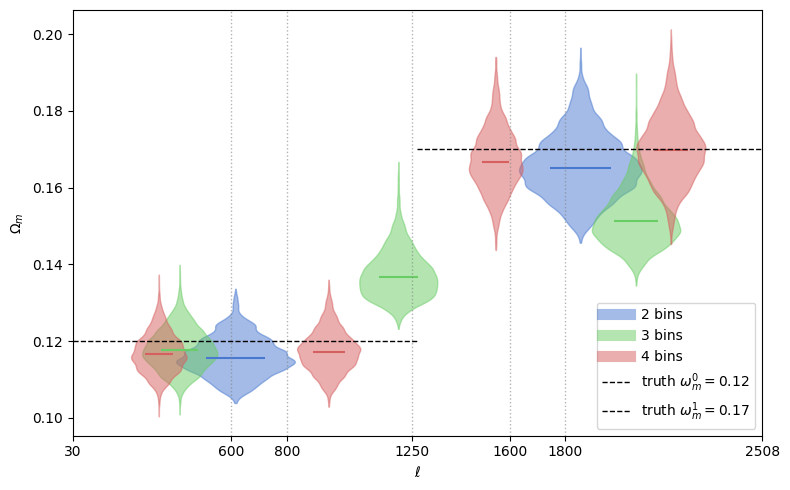

--- 2 bins ---
omega_m0: 0.1156 (+0.0056 / -0.0048)
omega_m1: 0.1652 (+0.0090 / -0.0075)
--- 3 bins ---
omega_m0: 0.1176 (+0.0058 / -0.0052)
omega_m1: 0.1367 (+0.0070 / -0.0053)
omega_m2: 0.1512 (+0.0079 / -0.0059)
--- 4 bins ---
omega_m0: 0.1166 (+0.0056 / -0.0049)
omega_m1: 0.1173 (+0.0056 / -0.0052)
omega_m2: 0.1668 (+0.0083 / -0.0075)
omega_m3: 0.1698 (+0.0091 / -0.0084)


In [15]:
# ---- example usage: 2-bin likelihood vs 3-bin analysis ----
# Fill in the actual switch points for your 3-bin analysis run --
# I don't know these, this is a placeholder split of the same ell range.
l_edges_2bin = (30, 1250, 2508)
l_edges_3bin = (30, 800, 1600, 2508)   
l_edges_4bin = (30, 600, 1250, 1800, 2508)   

ax, results = plot_omegam_violin_multi(
    groups=[
        dict(samp=samp2, prefix="omega_m", l_edges=l_edges_2bin,
             color="C0", label="2 bins"),
        dict(samp=samp3, prefix="omega_m", l_edges=l_edges_3bin,
             color="C1", label="3 bins"),
        dict(samp=samp4, prefix="omega_m", l_edges=l_edges_4bin,
             color="C2", label="4 bins"),
    ],
)
plt.tight_layout()
plt.show()

for res in results:
    print(f"--- {res['label']} ---")
    for name in res["param_names"]:
        vals = res["resampled"][name]
        lo, med, hi = np.percentile(vals, [16, 50, 84])
        print(f"{name}: {med:.4f} (+{hi-med:.4f} / -{med-lo:.4f})")